# 356. Does a search call land on one exon's residues? (midi-plus, chicken and zebrafish)

**Question.** A human query protein is searched against chicken or zebrafish. When a tool
calls a region of the target protein, does that call sit on the residues one exon codes,
or does it spread over the whole protein? Notebook
[244](https://github.com/seanome/2024-kmerseek-analysis/pull/49) asked this with short
Swiss-Prot features as the truth: kmerseek's call landed on 176 of 182 features, Foldseek
on 2 and ProstT5 on 3. Here the truth is the target protein's exons.

**What decision this informs.** If kmerseek lands on short exons and structure tools do
not, the paper can say that kmerseek places a match on a single exon, which structure
search cannot. If it fails, the exon claim stays out of the paper, and nb 244's result is
about Swiss-Prot features only.

**Words.** A call *lands* on an exon when at least 80% of the call is inside the exon and
the call covers at least 30% of the exon (nb 244's rule). It *spills* when less than half
of the call is inside the exon. *Partial*: it overlaps the exon with at least half of
itself inside, but does not land. *No call*: no call between the two proteins touches the
exon. IoU is the overlap of the call and the exon divided by their union.

**Decision rule, written before the run**
([preregistered.md](356_data/preregistered.md), with its 2026-10-20 amendments). On
internal coding exons of 60 residues or fewer, on pairs where both proteins have an
AlphaFold model:

1. kmerseek (best of all settings) lands on at least 50% of them;
2. every structure tool (Foldseek, Reseek, ProstT5) lands on under 15%;
3. kmerseek's landing rate, counting only calls whose placement p-value is below 0.05,
   is at least twice the Kyte-Doolittle scan's.

Pass needs all three. Stop 0 also stops the work if kmerseek lands on under 10% of short
exons, or if the Kyte-Doolittle scan lands as often as kmerseek (then the result is about
amino-acid composition, not search).

**Data.** The midi-plus run (1-8 Sept 2026): 998 human queries (chromosome 6, plus B2M,
CD1A-E, MR1, KIR and LILR) searched against the nine QfO 2020_04 proteomes, image
`olgabot/kmerseek:2026-08-24-reduced-alphabets`. Query = human; target database = the
chicken (UP000000539) or zebrafish (UP000000437) proteome. Only calls between a query and
its 1:1 OMA ortholog are scored. kmerseek calls are kept at Bonferroni p < 0.05, as in
nb 244. Exons come from UniProt's exon map for the same protein sequences (the QfO
release's `_gcoord.xml`).

In [1]:
import json
import sys
from pathlib import Path

import polars as pl

sys.path.insert(0, str(Path.cwd()))
import exon_landing_356 as el

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(200)
STAGE = "full"
TABLES = Path("../tables/356")
FIG = Path("../figures/356")
d = el.load(TABLES)
v = d["verdict"]
inputs = json.loads(Path("356_data/exon_inputs.json").read_text())
et = d["exon_tool"]
one_tool = et.filter(pl.col("tool") == "kmerseek_best_of_all")
print(f"stage: {v['stage']}; pairs scored: {v['n_pairs']}")
print(
    one_tool.group_by("species").agg(
        pairs=pl.struct("query_acc", "target_acc").n_unique(),
        exons=pl.len(),
        internal=pl.col("internal").sum(),
        internal_le60=pl.col("short_internal").sum(),
        both_models=pl.col("both_models").sum(),
        verdict_exons=pl.col("verdict_set").sum(),
    )
)

stage: full; pairs scored: 546
shape: (2, 7)
┌───────────┬───────┬───────┬──────────┬───────────────┬─────────────┬───────────────┐
│ species   ┆ pairs ┆ exons ┆ internal ┆ internal_le60 ┆ both_models ┆ verdict_exons │
│ ---       ┆ ---   ┆ ---   ┆ ---      ┆ ---           ┆ ---         ┆ ---           │
│ str       ┆ u32   ┆ u32   ┆ u32      ┆ u32           ┆ u32         ┆ u32           │
╞═══════════╪═══════╪═══════╪══════════╪═══════════════╪═════════════╪═══════════════╡
│ chicken   ┆ 203   ┆ 1860  ┆ 1465     ┆ 1213          ┆ 791         ┆ 516           │
│ zebrafish ┆ 338   ┆ 3021  ┆ 2375     ┆ 1965          ┆ 1833        ┆ 1153          │
└───────────┴───────┴───────┴──────────┴───────────────┴─────────────┴───────────────┘


## 1. Verdict against the pre-registered rules

Each row is one rule with the count behind it. Higher landing is better for kmerseek; for
structure tools the rule asks for low landing, because nb 244 found that they cover the
whole protein.

shape: (6, 5)
┌─────────────────────────────────┬────────┬─────────┬───────┬──────┐
│ rule                            ┆ n_land ┆ n_exons ┆ rate  ┆ pass │
│ ---                             ┆ ---    ┆ ---     ┆ ---   ┆ ---  │
│ str                             ┆ i64    ┆ i64     ┆ f64   ┆ bool │
╞═════════════════════════════════╪════════╪═════════╪═══════╪══════╡
│ 1: kmerseek best of all lands … ┆ 1129   ┆ 1669    ┆ 0.676 ┆ true │
│ 2: foldseek lands < 15%         ┆ 0      ┆ 1669    ┆ 0.0   ┆ true │
│ 2: reseek lands < 15%           ┆ 0      ┆ 1669    ┆ 0.0   ┆ true │
│ 2: prostt5 lands < 15%          ┆ 0      ┆ 1669    ┆ 0.0   ┆ true │
│ 3: kmerseek lands with p_place… ┆ 675    ┆ 1669    ┆ 0.404 ┆ null │
│ 3: Kyte-Doolittle scan lands    ┆ 82     ┆ 1669    ┆ 0.049 ┆ null │
└─────────────────────────────────┴────────┴─────────┴───────┴──────┘
rule 3 ratio (kmerseek / scan): 8.231707317073171; pass: True
random-protein null of kmerseek's best of all: median 0.620, 99.9th percentile 0.651

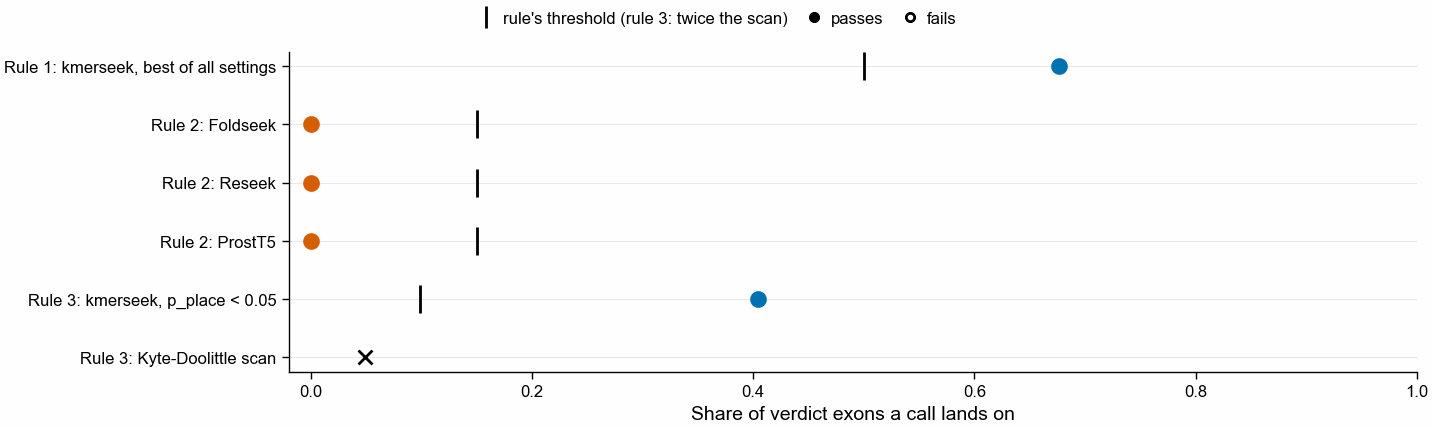

In [2]:
rows = [
    (
        "1: kmerseek best of all lands >= 50%",
        *v["rule_1"]["kmerseek_best_of_all_lands"],
        v["rule_1"]["pass"],
    ),
    *[
        (f"2: {t} lands < 15%", *x, x[2] is not None and x[2] < 0.15)
        for t, x in v["rule_2"]["structure_tools_land"].items()
    ],
    (
        "3: kmerseek lands with p_place < 0.05",
        *v["rule_3"]["kmerseek_lands_with_p_place_lt_0.05"],
        None,
    ),
    ("3: Kyte-Doolittle scan lands", *v["rule_3"]["kd_scan_lands"], None),
]
verdict_tab = pl.DataFrame(
    rows, schema=["rule", "n_land", "n_exons", "rate", "pass"], orient="row"
)
print(verdict_tab.with_columns(pl.col("rate").round(3)))
print(
    f"rule 3 ratio (kmerseek / scan): {v['rule_3']['ratio']}; pass: {v['rule_3']['pass']}"
)
print(
    f"random-protein null of kmerseek's best of all: median {v['random_protein_null']['median']:.3f}, "
    f"99.9th percentile {v['random_protein_null']['quantile_0.999']:.3f}; "
    f"observed above it: {v['random_protein_null']['observed_above_0.999']}"
)
print(
    f"Stop 0 empty question (kmerseek < 10%): {v['empty_question_kmerseek_below_0.10']}"
)
print(
    f"Stop 0 kill condition (scan at kmerseek's rate): {v['kill_condition_kd_at_kmerseek_rate']}"
)
print(f"OVERALL PASS: {v['pass']}")
vfig = el.verdict_figure(d, FIG / "356_verdict_rules_midi_plus_chicken_zebrafish")

## 2. Landing rate by exon length (Figure 1)

How to read it: each line is one tool; a point is the share of exons in that length bin
that some call of the tool lands on. The grey band is the exons the rules use. A tool
that places calls on single exons sits high on the left; a tool whose calls cover whole
proteins sits near zero everywhere except, perhaps, the longest exons.

shape: (11, 6)
┌──────────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ tool                 ┆ <=20     ┆ 21-40    ┆ 41-60    ┆ 61-120   ┆ >120     │
│ ---                  ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str                  ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞══════════════════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ foldseek             ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0      │
│ hhblits              ┆ 0.007246 ┆ 0.035354 ┆ 0.052774 ┆ 0.057971 ┆ 0.039216 │
│ hmmer3_jackhmmer     ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.078431 │
│ hmmer3_phmmer        ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.078431 │
│ kd_scan              ┆ 0.0      ┆ 0.034091 ┆ 0.074425 ┆ 0.054348 ┆ 0.0      │
│ kmerseek_best_of_all ┆ 0.369565 ┆ 0.657828 ┆ 0.753721 ┆ 0.695652 ┆ 0.27451  │
│ kmerseek_best_single ┆ 0.123188 ┆ 0.348485 ┆ 0.288227 ┆ 0.213768 ┆ 0.098039 │
│ mmseqs2_iterative    ┆ 

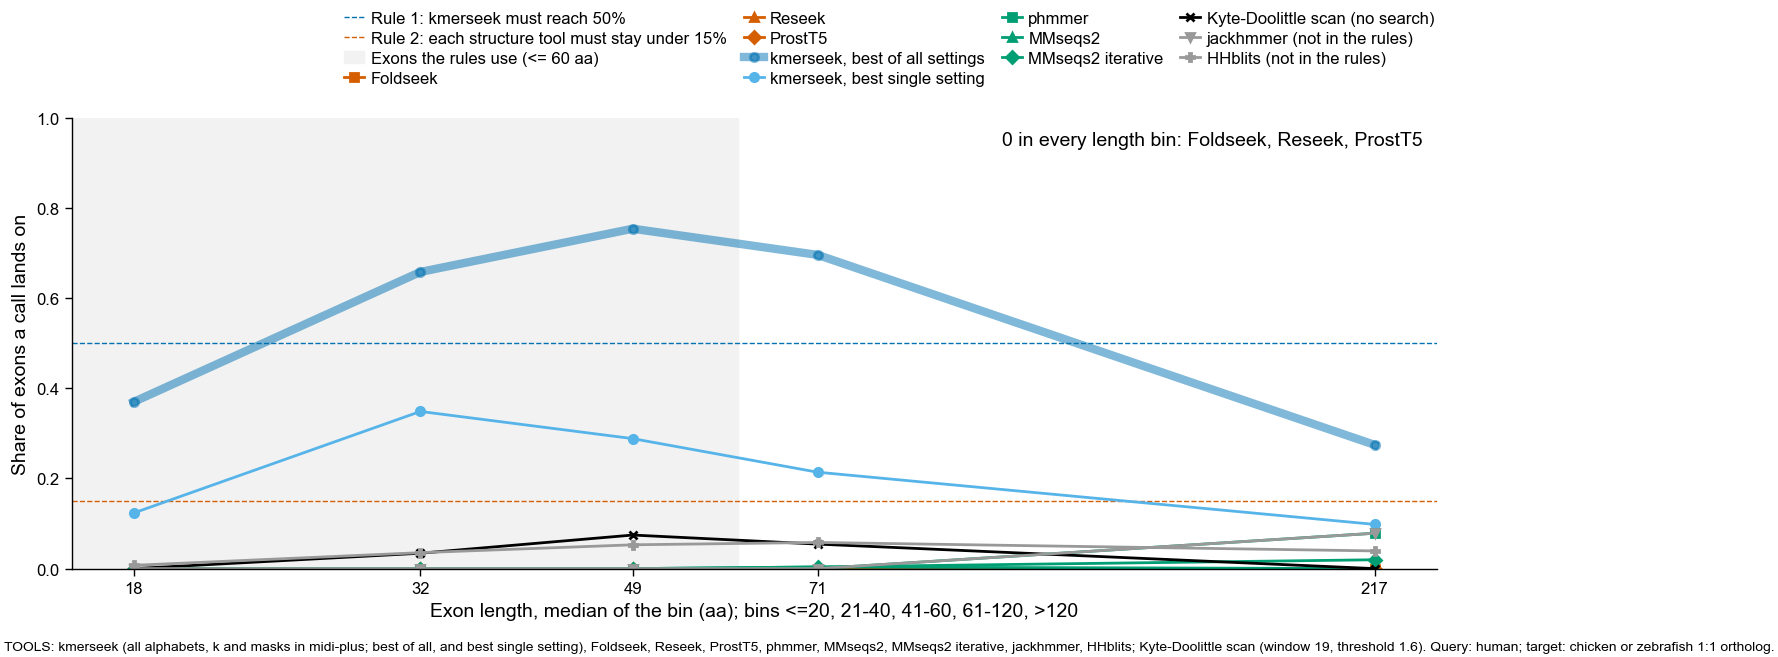

In [3]:
tools_line = (
    "TOOLS: kmerseek (all alphabets, k and masks in midi-plus; best of all, and best single setting), "
    "Foldseek, Reseek, ProstT5, phmmer, MMseqs2, MMseqs2 iterative, jackhmmer, HHblits; "
    "Kyte-Doolittle scan (window 19, threshold 1.6). Query: human; target: chicken or zebrafish 1:1 ortholog."
)
fig1 = el.landing_by_length(
    d, FIG / "356_fig1_landing_by_exon_length_midi_plus_chicken_zebrafish", tools_line
)
print(
    fig1.pivot(on="length_bin", index="tool", values="rate").select(
        "tool", *[b for b in el.BIN_ORDER if b in fig1["length_bin"].unique()]
    )
)

## 3. What each tool's call does on the short exons (SF2)

For each tool, the verdict exons split by outcome: lands, partial, spills, no call.

shape: (11, 6)
┌──────────────────────┬───────┬─────────┬────────┬─────────┬──────┐
│ tool                 ┆ lands ┆ partial ┆ spills ┆ no call ┆ n    │
│ ---                  ┆ ---   ┆ ---     ┆ ---    ┆ ---     ┆ ---  │
│ str                  ┆ u32   ┆ u32     ┆ u32    ┆ u32     ┆ u32  │
╞══════════════════════╪═══════╪═════════╪════════╪═════════╪══════╡
│ kd_scan              ┆ 82    ┆ 20      ┆ 37     ┆ 1530    ┆ 1669 │
│ kmerseek_best_of_all ┆ 1129  ┆ 278     ┆ 130    ┆ 132     ┆ 1669 │
│ hhblits              ┆ 68    ┆ 84      ┆ 1484   ┆ 33      ┆ 1669 │
│ hmmer3_phmmer        ┆ 0     ┆ 4       ┆ 1653   ┆ 12      ┆ 1669 │
│ kmerseek_best_single ┆ 506   ┆ 478     ┆ 290    ┆ 395     ┆ 1669 │
│ mmseqs2_iterative    ┆ 0     ┆ 2       ┆ 1644   ┆ 23      ┆ 1669 │
│ prostt5              ┆ 0     ┆ 2       ┆ 1605   ┆ 62      ┆ 1669 │
│ hmmer3_jackhmmer     ┆ 0     ┆ 4       ┆ 1655   ┆ 10      ┆ 1669 │
│ mmseqs2_seqseq       ┆ 0     ┆ 2       ┆ 1647   ┆ 20      ┆ 1669 │
│ foldseek         

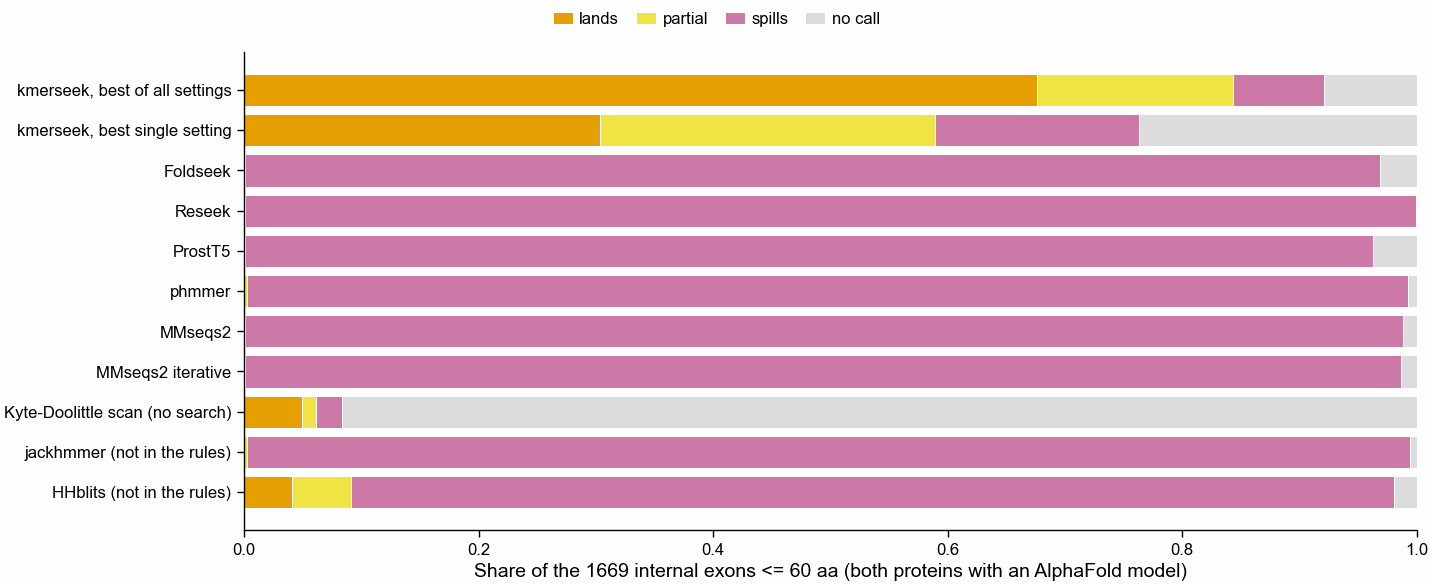

In [4]:
sf2 = el.outcome_shares(
    d, FIG / "356_sf2_outcome_shares_short_internal_exons_midi_plus"
)
print(sf2)

## 4. How tight the landing calls are (SF1)

Median IoU of the landing call, by exon-length bin, over the exons where the tool lands.
Higher is a tighter fit to the exon.

shape: (23, 5)
┌──────────────────────┬────────────┬─────┬────────────┬───────┐
│ tool                 ┆ length_bin ┆ n   ┆ median_iou ┆ x     │
│ ---                  ┆ ---        ┆ --- ┆ ---        ┆ ---   │
│ str                  ┆ str        ┆ u32 ┆ f64        ┆ f64   │
╞══════════════════════╪════════════╪═════╪════════════╪═══════╡
│ hhblits              ┆ <=20       ┆ 1   ┆ 0.316      ┆ 19.0  │
│ hhblits              ┆ 21-40      ┆ 28  ┆ 0.617      ┆ 33.0  │
│ hhblits              ┆ 41-60      ┆ 39  ┆ 0.449      ┆ 51.0  │
│ hhblits              ┆ 61-120     ┆ 16  ┆ 0.414      ┆ 77.5  │
│ hhblits              ┆ >120       ┆ 2   ┆ 0.526      ┆ 270.5 │
│ hmmer3_jackhmmer     ┆ >120       ┆ 4   ┆ 0.429      ┆ 281.5 │
│ hmmer3_phmmer        ┆ >120       ┆ 4   ┆ 0.636      ┆ 217.5 │
│ kd_scan              ┆ 21-40      ┆ 27  ┆ 0.647      ┆ 35.0  │
│ kd_scan              ┆ 41-60      ┆ 55  ┆ 0.404      ┆ 52.0  │
│ kd_scan              ┆ 61-120     ┆ 15  ┆ 0.333      ┆ 65.0  │
│ kmerseek

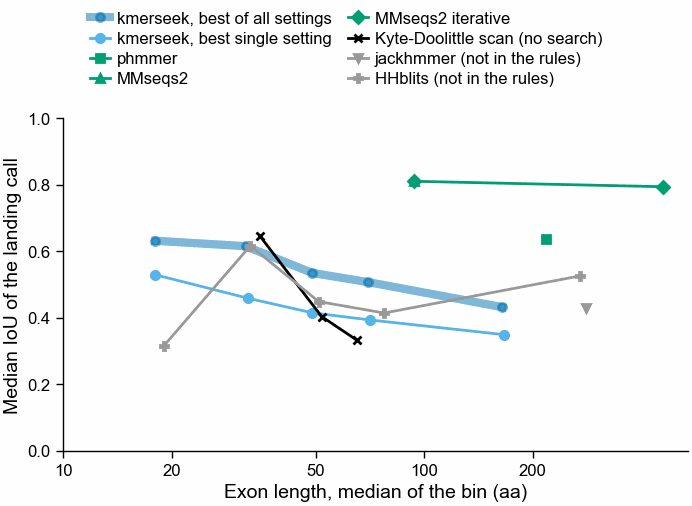

In [5]:
sf1 = el.iou_by_length(d, FIG / "356_sf1_median_iou_by_exon_length_midi_plus")
print(sf1.with_columns(pl.col("median_iou").round(3)))

## 5. Ordered against disordered exons (SF3)

Exons split by the mean AlphaFold pLDDT of their residues on the target (ordered >= 70,
disordered < 70). Structure tools are expected to do worse on disordered exons.

shape: (22, 5)
┌──────────────────────┬────────────┬──────┬─────────┬───────┐
│ tool                 ┆ disorder   ┆ n    ┆ n_lands ┆ rate  │
│ ---                  ┆ ---        ┆ ---  ┆ ---     ┆ ---   │
│ str                  ┆ str        ┆ u32  ┆ u32     ┆ f64   │
╞══════════════════════╪════════════╪══════╪═════════╪═══════╡
│ foldseek             ┆ disordered ┆ 296  ┆ 0       ┆ 0.0   │
│ foldseek             ┆ ordered    ┆ 1373 ┆ 0       ┆ 0.0   │
│ hhblits              ┆ disordered ┆ 296  ┆ 9       ┆ 0.03  │
│ hhblits              ┆ ordered    ┆ 1373 ┆ 59      ┆ 0.043 │
│ hmmer3_jackhmmer     ┆ disordered ┆ 296  ┆ 0       ┆ 0.0   │
│ hmmer3_jackhmmer     ┆ ordered    ┆ 1373 ┆ 0       ┆ 0.0   │
│ hmmer3_phmmer        ┆ disordered ┆ 296  ┆ 0       ┆ 0.0   │
│ hmmer3_phmmer        ┆ ordered    ┆ 1373 ┆ 0       ┆ 0.0   │
│ kd_scan              ┆ disordered ┆ 296  ┆ 7       ┆ 0.024 │
│ kd_scan              ┆ ordered    ┆ 1373 ┆ 75      ┆ 0.055 │
│ kmerseek_best_of_all ┆ disordered ┆ 29

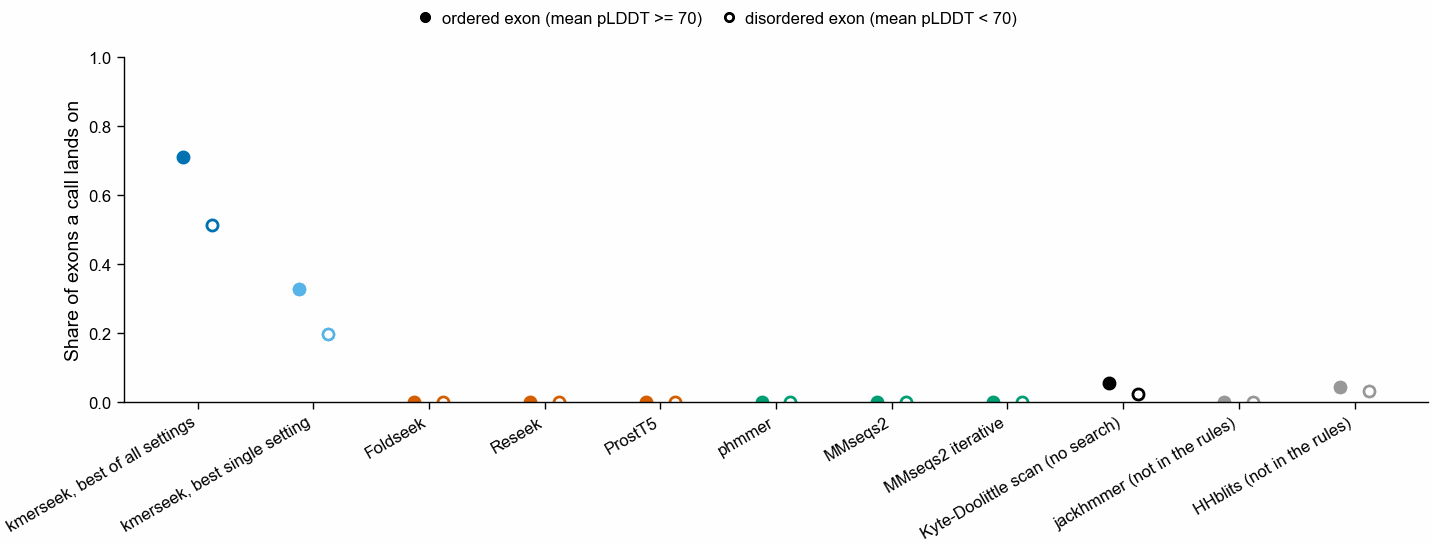

In [6]:
sf3 = el.landing_by_disorder(d, FIG / "356_sf3_landing_by_exon_disorder_midi_plus")
print(sf3.with_columns(pl.col("rate").round(3)))

## 6. kmerseek's best of all settings against chance

(a) Every kmerseek setting's landing rate on the verdict exons, with the best of all
settings as a line. (b) The same best-of-all rule scored on decoys: each exon's interval
moved, at the same coordinates, onto another pair's target protein. If the real rate sits
inside the null, landing on an exon is something kmerseek's short matches do anywhere.

shape: (3, 5)
┌─────────────────────────────────┬────────────┬─────────────┬───────────┬────────────┐
│ kmerseek number                 ┆ real exons ┆ null median ┆ null 0.1% ┆ null 99.9% │
│ ---                             ┆ ---        ┆ ---         ┆ ---       ┆ ---        │
│ str                             ┆ f64        ┆ f64         ┆ f64       ┆ f64        │
╞═════════════════════════════════╪════════════╪═════════════╪═══════════╪════════════╡
│ best of all settings            ┆ 0.676      ┆ 0.62        ┆ 0.585     ┆ 0.651      │
│ best of all, p_place < 0.05     ┆ 0.404      ┆ 0.376       ┆ 0.34      ┆ 0.409      │
│ best single setting (sdm12_k6_… ┆ 0.303      ┆ 0.271       ┆ 0.242     ┆ 0.301      │
└─────────────────────────────────┴────────────┴─────────────┴───────────┴────────────┘
shape: (10, 4)
┌────────────────────────┬────────┬─────────┬──────────┐
│ arm                    ┆ n_land ┆ n_exons ┆ rate     │
│ ---                    ┆ ---    ┆ ---     ┆ ---      │
│ str   

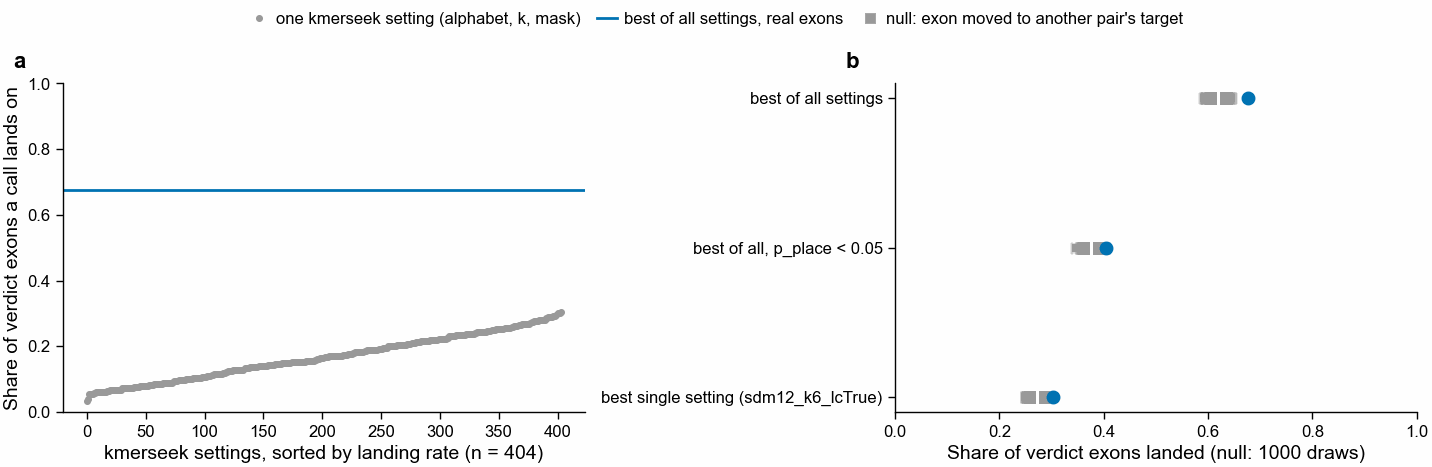

In [7]:
null_tab = el.settings_and_null(
    d, FIG / "356_kmerseek_settings_and_random_protein_null_midi_plus"
)
print(null_tab.with_columns(pl.col(pl.Float64).round(3)))
print(d["settings"].head(10))

## 7. Are the landing calls at the aligned position? (added after Stop 1)

Not in the pre-registration. For every verdict exon kmerseek lands on, each landing call
is checked against a global alignment of the human query and its ortholog (Biopython,
BLOSUM62, gap open -11, extend -1). A call is *on position* when at least half of its
residue pairs are pairs the global alignment also makes. This catches a call that lands
on the exon but pairs it with the wrong stretch of the human protein, as in a repeat.

verdict exons kmerseek lands on: 1129
  with at least one landing call on position: 1097


shape: (2, 3)
┌─────────────────┬───────┬─────────────────┐
│ any_on_position ┆ exons ┆ median_settings │
│ ---             ┆ ---   ┆ ---             │
│ bool            ┆ u32   ┆ f64             │
╞═════════════════╪═══════╪═════════════════╡
│ false           ┆ 32    ┆ 9.0             │
│ true            ┆ 1097  ┆ 66.0            │
└─────────────────┴───────┴─────────────────┘


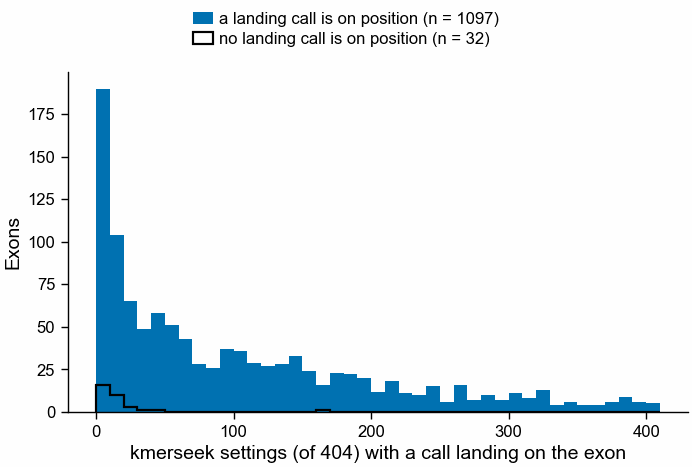

In [8]:
onpos = pl.read_parquet(TABLES / "landing_on_position.parquet")
hero = json.loads((TABLES / "hero.json").read_text())
print(f"verdict exons kmerseek lands on: {hero['n_verdict_exons_landed']}")
print(
    f"  with at least one landing call on position: {hero['n_landed_with_a_call_on_position']}"
)
print(
    el.on_position_figure(
        onpos, FIG / "356_landing_on_position_global_alignment_midi_plus"
    )
)

## 8. Hero exon

Rule, written before looking: a verdict exon that is disordered (mean pLDDT < 70), where
kmerseek's best of all lands with p_place < 0.05 and Foldseek, Reseek, ProstT5, phmmer,
MMseqs2 and MMseqs2 iterative all spill; highest landing IoU, then smallest p_place.
Its first pick is shown with both kmerseek calls that land on it: the one with IoU 1.0
pairs the exon with the wrong copy of the collagen repeat, and a second setting pairs it
with the aligned residues. (a) the whole chicken protein, every tool's call on the pair;
(b) the same around the exon; (c) the residues of both kmerseek calls, classes underneath.

shape: (2, 20)
┌─────────┬───────────┬────────────┬────────────────────┬───┬──────────────────┬─────────────┬─────────────────────────────┬───────────────────────────┐
│ species ┆ query_acc ┆ target_acc ┆ exon_id            ┆ … ┆ frac_on_position ┆ n_identical ┆ aligned_target_start_1based ┆ aligned_target_end_1based │
│ ---     ┆ ---       ┆ ---        ┆ ---                ┆   ┆ ---              ┆ ---         ┆ ---                         ┆ ---                       │
│ str     ┆ str       ┆ str        ┆ str                ┆   ┆ f64              ┆ i64         ┆ i64                         ┆ i64                       │
╞═════════╪═══════════╪════════════╪════════════════════╪═══╪══════════════════╪═════════════╪═════════════════════════════╪═══════════════════════════╡
│ chicken ┆ P20849    ┆ F1NQ20     ┆ ENSGALE00000298226 ┆ … ┆ 1.0              ┆ 11          ┆ 362                         ┆ 375                       │
│ chicken ┆ P20849    ┆ F1NQ20     ┆ ENSGALE00000298226 ┆ … ┆ 0.0  

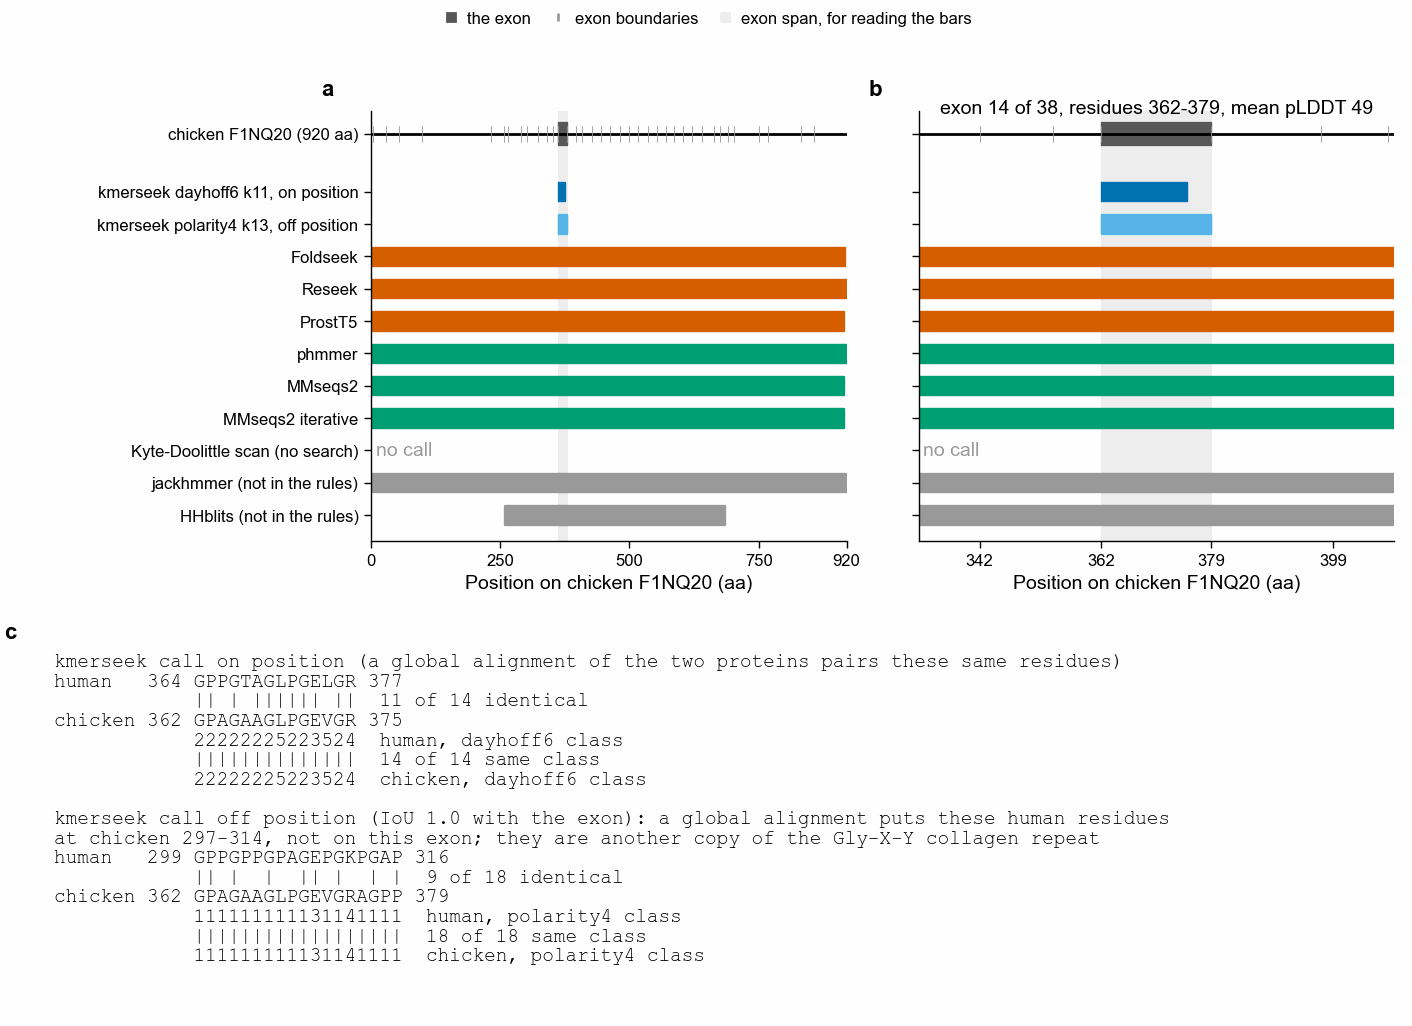

In [9]:
exons = pl.read_parquet("356_data/exons.parquet")
el.hero_figure(hero, et, exons, FIG / "356_hero_col9a1_chicken_exon14_midi_plus")
print(
    pl.DataFrame(
        [
            {k: v for k, v in hero[c].items() if not k.endswith("residues")}
            for c in ("hero_on_position", "rule_first_pick")
        ]
    )
)

## Summary and conclusions (Stop 1, all pairs, 2026-10-20)

**Data.** All 546 1:1 ortholog pairs; 541 have exon truth (203 chicken, 338 zebrafish).
They hold 3,178 internal exons of 60 residues or fewer, and 1,669 of those are on pairs
where both proteins have an AlphaFold model (the verdict set). The Stop 0 pilot (200
pairs, 614 verdict exons) is in `tables/356/pilot/` and `figures/356/pilot/`.

**Under the pre-registered rule, all three parts pass.**

1. kmerseek's best of all 404 settings lands on 1,129 of 1,669 short exons (68%; rule:
   at least 50%).
2. Foldseek, Reseek and ProstT5 each land on 0 of 1,669 (rule: under 15%). They spill
   on 1,615, 1,666 and 1,605 of them: one call over most of the protein.
3. Counting only landing calls with a placement p-value below 0.05, kmerseek lands on 675
   (40%), 8.2 times the Kyte-Doolittle scan's 82 (5%; rule: at least 2 times).

**Against the random-protein null, kmerseek beats chance, but by a small margin.** Each
exon's interval was moved, at the same coordinates, onto the target protein of another
pair of the same species, and scored against that pair's kmerseek calls (1,000 draws).

| kmerseek number | real exons | null median | null max | draws at or above real | exons above the null median |
|---|---|---|---|---|---|
| best of all settings (pre-registered null) | 67.6% | 62.0% | 65.3% | 0 of 1,000 | 95 |
| best of all, p_place < 0.05 (added after Stop 0) | 40.4% | 37.6% | 41.0% | 11 of 1,000 | 48 |
| best single setting, sdm12 k 6, mask on (added after Stop 0) | 30.3% | 27.1% | 30.4% | 1 of 1,000 | 53 |

The pre-registered null for the best of all settings is beaten at p < 0.001 (no draw
reaches the real rate). The excess is about 95 of 1,669 exons; the other ~1,034 landings
happen at the same rate on an interval that is not the exon. The placement-filtered rate
is inside its null. The best single setting was chosen on these same exons, so its null
comparison favours it; it is shown for scale, not as a test.

**Why most landings are chance.** kmerseek's calls are short gapless runs along both
proteins. A short run inside any 20-60 residue stretch passes the landing rule (80% of
the call inside, 30% of the stretch covered), whether or not the stretch is an exon. The
rule's other controls (structure tools, aligners, the scan) make long calls or almost
none, so none of them measures this; only the null does.

**Conclusion.** On 1,669 short internal exons of chicken and zebrafish orthologs of the
midi-plus queries, kmerseek's calls land on the exon about 6 percentage points more often
than on the same coordinates of an unrelated ortholog pair (67.6% against a null median
of 62.0%, p < 0.001 over 1,000 draws); structure tools and aligners never land, because
they cover the whole protein. The pre-registered rule passes, but its 50% threshold is
met mostly by chance landings. The defensible claim is the excess over the null, not the
68%.

**Smaller points.** kmerseek lands more often on ordered exons (977 of 1,373, 71%) than
on disordered ones (152 of 296, 51%); the null was not split by disorder, so this does
not say where the excess comes from. HHblits lands on 68 of 1,669; phmmer, MMseqs2,
MMseqs2 iterative and jackhmmer on none. Reseek target positions on 4 F-digit TrEMBL
accessions ran past the protein end and were corrected (the known fragment-offset bug).
The pre-registration planned Stop 1 as a Sherlock job; it ran on the laptop in 11 s
because the Sherlock job had already cut the calls to the pairs.

**Not done.** Stop 2: the second-agent check and the hero case. A tighter null that
moves the interval along the same protein, or keeps only decoys whose ends fall on real
exon boundaries of the decoy protein, would say whether the 95-exon excess is about exon
boundaries or about which part of the protein the exon sits in.